# Experiment 10: Principal Component Analysis (PCA)

## Import libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

sns.set_theme(style="whitegrid")
np.random.seed(42)
RS = 42

## Load data

In [2]:
wine = load_wine(as_frame=True)
X, y = wine.data, wine.target
names = wine.target_names
print("Shape:", X.shape)
X.head()

Shape: (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## Standardize features

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Mean:", X_scaled.mean(axis=0).round(6)[:5], "...")
print("Std :", X_scaled.std(axis=0).round(6)[:5], "...")

Mean: [ 0.  0. -0. -0. -0.] ...
Std : [1. 1. 1. 1. 1.] ...


## PCA from first principles: covariance matrix and eigen-decomposition

In [4]:
cov = np.cov(X_scaled, rowvar=False)
display(pd.DataFrame(cov, index=X.columns, columns=X.columns).round(2).iloc[:5, :5])

eig_vals, eig_vecs = np.linalg.eigh(cov)
order = np.argsort(eig_vals)[::-1]
eig_vals, eig_vecs = eig_vals[order], eig_vecs[:, order]
print("Eigenvalues:", eig_vals.round(4))
print("Sum of eigenvalues (= number of features):", eig_vals.sum().round(4))

explained_manual = eig_vals / eig_vals.sum()
manual_scores = X_scaled @ eig_vecs
pd.DataFrame({"eigenvalue": eig_vals, "explained_ratio": explained_manual, "cumulative": np.cumsum(explained_manual)},
             index=[f"PC{i+1}" for i in range(len(eig_vals))]).round(4)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium
alcohol,1.01,0.09,0.21,-0.31,0.27
malic_acid,0.09,1.01,0.16,0.29,-0.05
ash,0.21,0.16,1.01,0.45,0.29
alcalinity_of_ash,-0.31,0.29,0.45,1.01,-0.08
magnesium,0.27,-0.05,0.29,-0.08,1.01


Eigenvalues: [4.7324 2.5111 1.4542 0.9242 0.858  0.6453 0.5541 0.3505 0.2905 0.2523
 0.2271 0.1697 0.104 ]
Sum of eigenvalues (= number of features): 13.0734


,eigenvalue,explained_ratio,cumulative
PC1,4.7324,0.3620,0.3620
PC2,2.5111,0.1921,0.5541
PC3,1.4542,0.1112,0.6653
PC4,0.9242,0.0707,0.7360
PC5,0.8580,0.0656,0.8016
PC6,0.6453,0.0494,0.8510
PC7,0.5541,0.0424,0.8934
PC8,0.3505,0.0268,0.9202
PC9,0.2905,0.0222,0.9424
PC10,0.2523,0.0193,0.9617


## PCA with scikit-learn

In [5]:
pca = PCA(random_state=RS)
X_pca = pca.fit_transform(X_scaled)
print("Components shape:", pca.components_.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

print("Eigenvalues match explained variance:", np.allclose(eig_vals, pca.explained_variance_))
print("Scores match (up to sign):", np.allclose(np.abs(manual_scores), np.abs(X_pca)))

Components shape: (13, 13)
Explained variance ratio: [0.362  0.1921 0.1112 0.0707 0.0656 0.0494 0.0424 0.0268 0.0222 0.0193
 0.0174 0.013  0.008 ]
Eigenvalues match explained variance: True
Scores match (up to sign): True


## Scree plot and cumulative explained variance

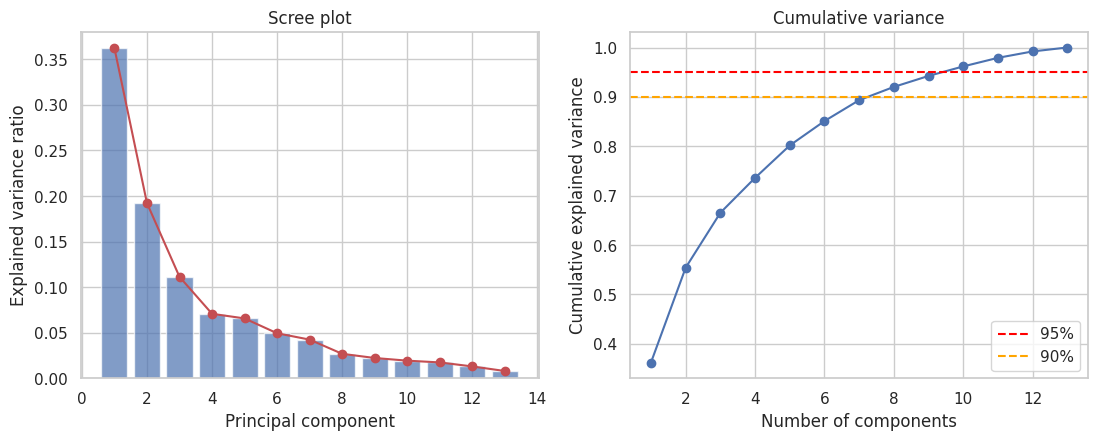

Components for 90% variance: 8
Components for 95% variance: 10
Components with eigenvalue > 1 (Kaiser): 3


In [6]:
ratio = pca.explained_variance_ratio_
cum = np.cumsum(ratio)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(range(1, len(ratio) + 1), ratio, alpha=0.7)
axes[0].plot(range(1, len(ratio) + 1), ratio, "ro-")
axes[0].set_xlabel("Principal component"); axes[0].set_ylabel("Explained variance ratio"); axes[0].set_title("Scree plot")
axes[1].plot(range(1, len(cum) + 1), cum, "bo-")
axes[1].axhline(0.95, color="red", linestyle="--", label="95%")
axes[1].axhline(0.90, color="orange", linestyle="--", label="90%")
axes[1].set_xlabel("Number of components"); axes[1].set_ylabel("Cumulative explained variance"); axes[1].set_title("Cumulative variance"); axes[1].legend()
plt.show()

print("Components for 90% variance:", np.argmax(cum >= 0.90) + 1)
print("Components for 95% variance:", np.argmax(cum >= 0.95) + 1)
print("Components with eigenvalue > 1 (Kaiser):", (pca.explained_variance_ > 1).sum())

## Transformed feature space

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,class
0,3.316751,1.443463,-0.165739,-0.215631,0.693043,0.223880,0.596427,-0.065139,-0.641443,1.020956,-0.451563,0.540810,-0.066239,class_0
1,2.209465,-0.333393,-2.026457,-0.291358,-0.257655,0.927120,0.053776,-1.024416,0.308847,0.159701,-0.142657,0.388238,0.003637,class_0
2,2.516740,1.031151,0.982819,0.724902,-0.251033,-0.549276,0.424205,0.344216,1.177834,0.113361,-0.286673,0.000584,0.021717,class_0
3,3.757066,2.756372,-0.176192,0.567983,-0.311842,-0.114431,-0.383337,-0.643593,-0.052544,0.239413,0.759584,-0.242020,-0.369484,class_0
4,1.008908,0.869831,2.026688,-0.409766,0.298458,0.406520,0.444074,-0.416700,-0.326819,-0.078366,-0.525945,-0.216664,-0.079364,class_0


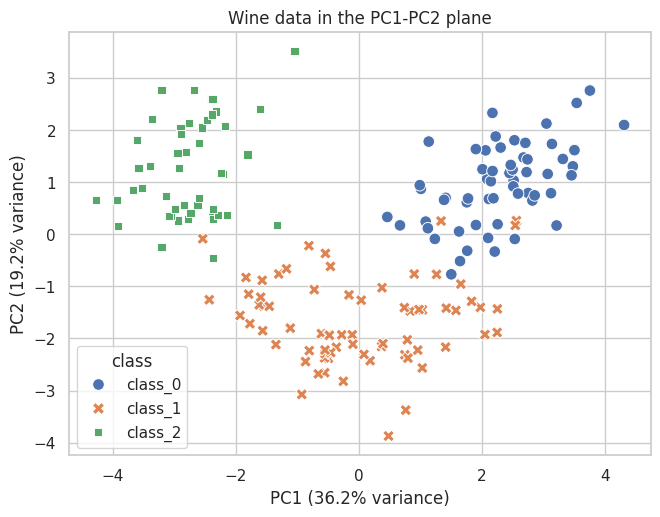

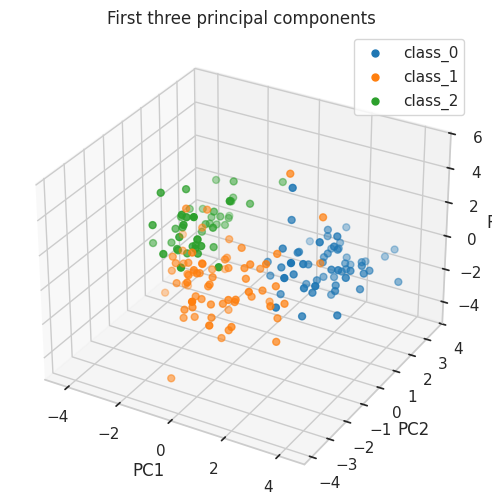

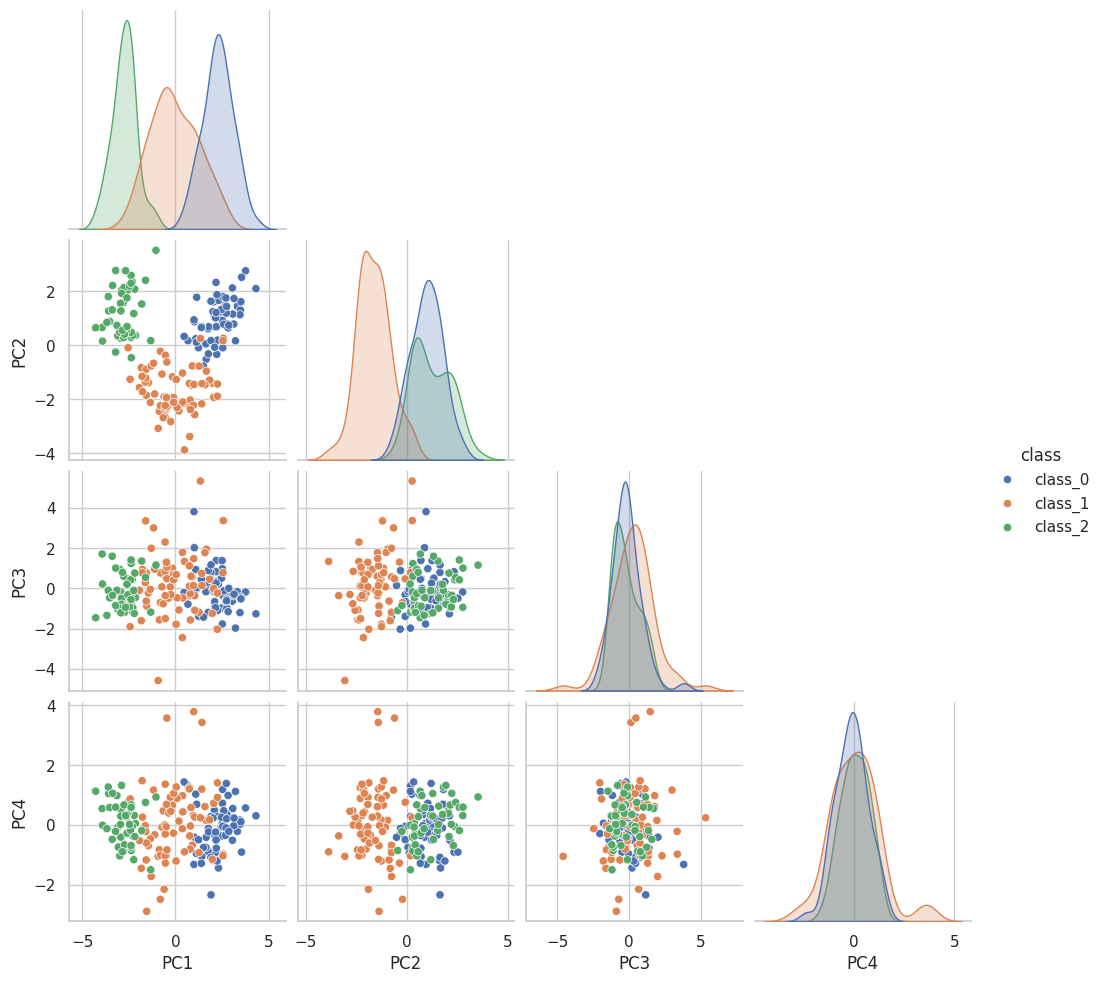

Correlation between PCs (should be ~0):


,0,1,2,3
0,1.0,-0.0,-0.0,0.0
1,-0.0,1.0,0.0,-0.0
2,-0.0,0.0,1.0,0.0
3,0.0,-0.0,0.0,1.0


In [7]:
pc_df = pd.DataFrame(X_pca, columns=[f"PC{i+1}" for i in range(X_pca.shape[1])])
pc_df["class"] = names[y]
display(pc_df.head())

plt.figure(figsize=(7.5, 5.5))
sns.scatterplot(data=pc_df, x="PC1", y="PC2", hue="class", style="class", s=70)
plt.xlabel(f"PC1 ({ratio[0]*100:.1f}% variance)"); plt.ylabel(f"PC2 ({ratio[1]*100:.1f}% variance)")
plt.title("Wine data in the PC1-PC2 plane")
plt.show()

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
for cls, color in zip(range(3), ["tab:blue", "tab:orange", "tab:green"]):
    m = y == cls
    ax.scatter(X_pca[m, 0], X_pca[m, 1], X_pca[m, 2], label=names[cls], c=color, s=25)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3"); ax.legend(); ax.set_title("First three principal components")
plt.show()

sns.pairplot(pc_df[["PC1", "PC2", "PC3", "PC4", "class"]], hue="class", corner=True)
plt.show()

print("Correlation between PCs (should be ~0):")
pd.DataFrame(X_pca[:, :4]).corr().round(6)

## Loadings

,PC1,PC2,PC3,PC4
alcohol,0.144,0.484,-0.207,-0.018
malic_acid,-0.245,0.225,0.089,0.537
ash,-0.002,0.316,0.626,-0.214
alcalinity_of_ash,-0.239,-0.011,0.612,0.061
magnesium,0.142,0.300,0.131,-0.352
total_phenols,0.395,0.065,0.146,0.198
flavanoids,0.423,-0.003,0.151,0.152
nonflavanoid_phenols,-0.299,0.029,0.170,-0.203
proanthocyanins,0.313,0.039,0.149,0.399
color_intensity,-0.089,0.530,-0.137,0.066


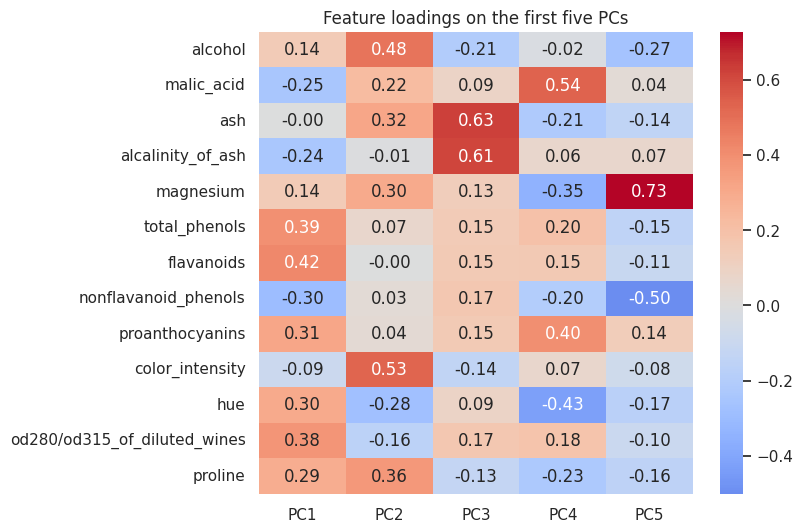

Features contributing most to PC1:


,PC1,PC2
flavanoids,0.423,-0.003
total_phenols,0.395,0.065
od280/od315_of_diluted_wines,0.376,-0.164
proanthocyanins,0.313,0.039
nonflavanoid_phenols,-0.299,0.029


In [8]:
loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=[f"PC{i+1}" for i in range(len(ratio))])
display(loadings.iloc[:, :4].round(3))

plt.figure(figsize=(7, 6))
sns.heatmap(loadings.iloc[:, :5], annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature loadings on the first five PCs")
plt.show()

top_pc1 = loadings["PC1"].abs().sort_values(ascending=False).head(5)
print("Features contributing most to PC1:")
loadings.loc[top_pc1.index, ["PC1", "PC2"]].round(3)

## Biplot

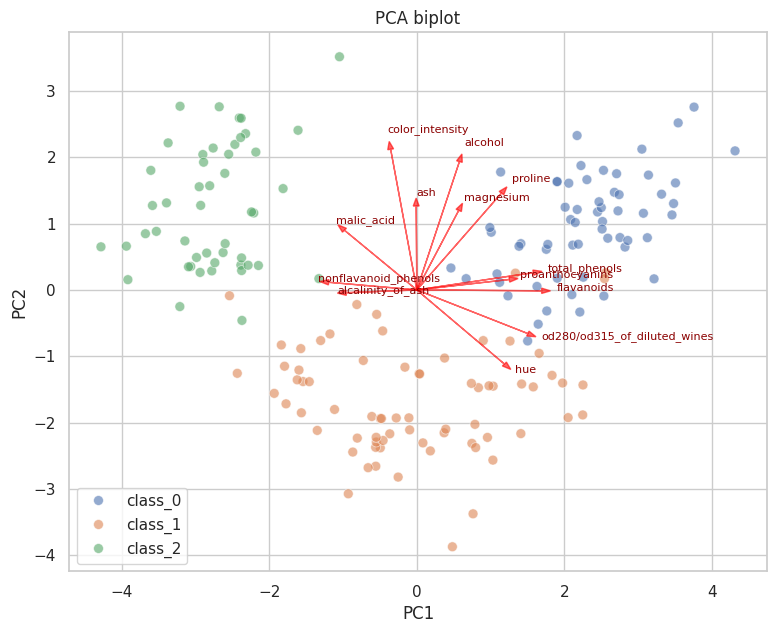

In [9]:
plt.figure(figsize=(9, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=names[y], alpha=0.6, s=50)
scale = 4
for feat in X.columns:
    plt.arrow(0, 0, loadings.loc[feat, "PC1"] * scale, loadings.loc[feat, "PC2"] * scale, color="red", alpha=0.6, head_width=0.08)
    plt.text(loadings.loc[feat, "PC1"] * scale * 1.12, loadings.loc[feat, "PC2"] * scale * 1.12, feat, color="darkred", fontsize=8)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PCA biplot")
plt.show()

## Reconstruction error

,components,reconstruction_MSE,variance_retained
0,1,0.6380,0.3620
1,2,0.4459,0.5541
2,3,0.3347,0.6653
3,4,0.2640,0.7360
4,5,0.1984,0.8016
5,6,0.1490,0.8510
6,7,0.1066,0.8934
7,8,0.0798,0.9202
8,9,0.0576,0.9424
9,10,0.0383,0.9617


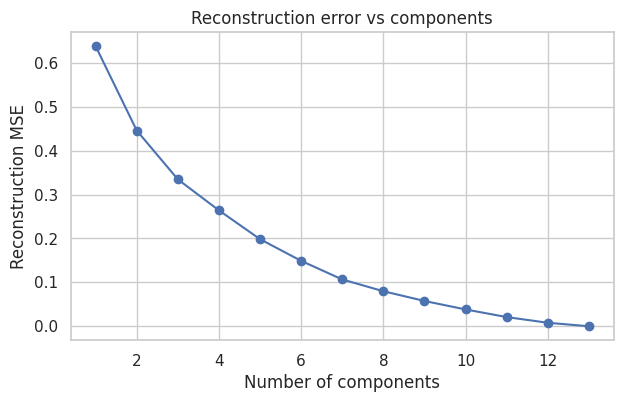

In [10]:
rows = []
for k in range(1, X.shape[1] + 1):
    p = PCA(n_components=k, random_state=RS).fit(X_scaled)
    recon = p.inverse_transform(p.transform(X_scaled))
    rows.append([k, np.mean((X_scaled - recon) ** 2), p.explained_variance_ratio_.sum()])
recon_df = pd.DataFrame(rows, columns=["components", "reconstruction_MSE", "variance_retained"])
display(recon_df.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(recon_df["components"], recon_df["reconstruction_MSE"], "o-")
ax.set_xlabel("Number of components"); ax.set_ylabel("Reconstruction MSE"); ax.set_title("Reconstruction error vs components")
plt.show()

## Effect of PCA on classification

In [11]:
rows = []
full = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)), X, y, cv=5).mean()
rows.append(["all 13 features", full])
for k in [2, 3, 5, 8, 10]:
    pipe = make_pipeline(StandardScaler(), PCA(n_components=k, random_state=RS), LogisticRegression(max_iter=5000))
    rows.append([f"{k} principal components", cross_val_score(pipe, X, y, cv=5).mean()])
pd.DataFrame(rows, columns=["features", "cv_accuracy"]).round(4)

,features,cv_accuracy
0,all 13 features,0.9832
1,2 principal components,0.9551
2,3 principal components,0.9610
3,5 principal components,0.9776
4,8 principal components,0.9778
5,10 principal components,0.9833


## PCA with and without standardization

Explained variance ratio WITHOUT scaling: [9.981e-01 1.700e-03 1.000e-04 1.000e-04]
Explained variance ratio WITH scaling   : [0.362  0.1921 0.1112 0.0707]


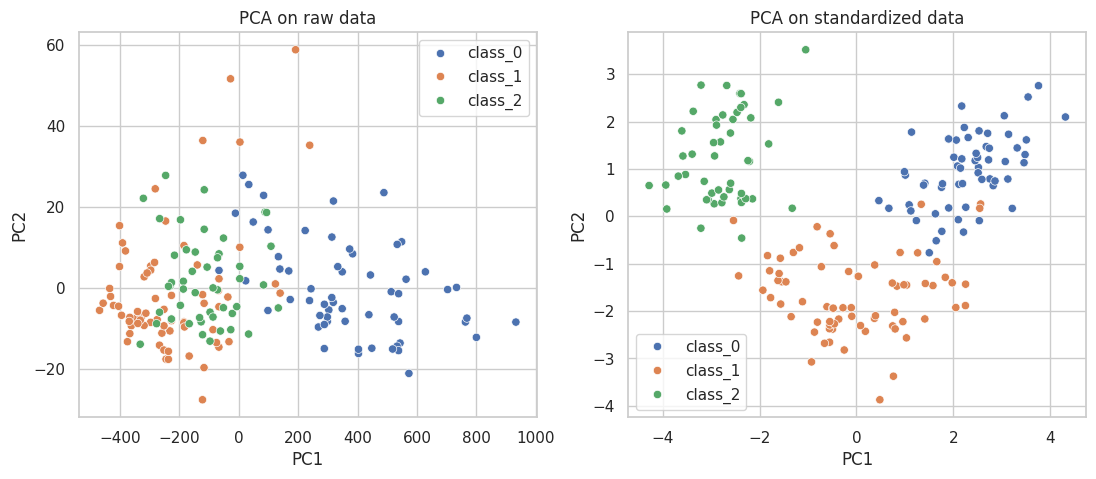

,PC1 loading (raw data)
proline,1.000
magnesium,0.018
alcohol,0.002
flavanoids,0.002


In [12]:
pca_raw = PCA(random_state=RS).fit(X)
print("Explained variance ratio WITHOUT scaling:", pca_raw.explained_variance_ratio_[:4].round(4))
print("Explained variance ratio WITH scaling   :", ratio[:4].round(4))

raw_scores = pca_raw.transform(X)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=raw_scores[:, 0], y=raw_scores[:, 1], hue=names[y], ax=axes[0]); axes[0].set_title("PCA on raw data")
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=names[y], ax=axes[1]); axes[1].set_title("PCA on standardized data")
for a in axes:
    a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.show()

pd.DataFrame(pca_raw.components_[0], index=X.columns, columns=["PC1 loading (raw data)"]).round(3).sort_values("PC1 loading (raw data)", ascending=False).head(4)